In [215]:
import numpy as np
import math
import pymc as pm
import pymc_bart as pmb
from pymc_bart.pgbart import PGBART
from numba import njit
import scipy as sp

# ==========================================
# 1. THE NUMBA ROULETTE WHEEL (SPARSITY)
# ==========================================
@njit
def sample_feature(alpha_vec):
    total_weight = np.sum(alpha_vec)
    r = np.random.uniform(0.0, total_weight)
    cumulative = 0.0
    for i in range(len(alpha_vec)):
        cumulative += alpha_vec[i]
        if r <= cumulative:
            return i
    return len(alpha_vec) - 1

@njit
def get_split_counts(F, num_features):
    counts = np.zeros(num_features, dtype=np.int32)
    m_trees = F.shape[0]
    max_nodes = F.shape[1]
    for m in range(m_trees):
        for i in range(max_nodes):
            feat = F[m, i]
            if feat != -1: counts[feat] += 1
    return counts

# ==========================================
# 2. THE MUTATIONS
# ==========================================
@njit
def get_active_leaves(F_tree, current_node_count):
    leaves = np.empty(current_node_count, dtype=np.int16)
    leaf_count = 0
    for i in range(current_node_count):
        if F_tree[i] == -1:
            leaves[leaf_count] = i
            leaf_count += 1
    return leaves[:leaf_count]

@njit
def propose_grow(tree_idx, X, F, T, L, R, V, D, node_counts, alpha_vec):
    current_count = node_counts[tree_idx]
    leaves = get_active_leaves(F[tree_idx], current_count)
    if current_count >= F.shape[1] - 1: return False, -1 
        
    random_idx = np.random.randint(0, len(leaves))
    leaf_to_split = leaves[random_idx]
    
    # NEW: Sparsity-aware feature selection
    split_feature = sample_feature(alpha_vec)
    feat_min, feat_max = np.min(X[:, split_feature]), np.max(X[:, split_feature])
    split_value = np.random.uniform(feat_min, feat_max)
    
    left_child_idx, right_child_idx = current_count, current_count + 1
    
    F[tree_idx, leaf_to_split] = split_feature
    T[tree_idx, leaf_to_split] = split_value
    L[tree_idx, leaf_to_split] = left_child_idx
    R[tree_idx, leaf_to_split] = right_child_idx
    F[tree_idx, left_child_idx] = -1
    F[tree_idx, right_child_idx] = -1
    
    # NEW: Update the Depth pointer
    parent_depth = D[tree_idx, leaf_to_split]
    D[tree_idx, left_child_idx] = parent_depth + 1
    D[tree_idx, right_child_idx] = parent_depth + 1

    # NEW: Inherit parent's value and add noise to the new leaves!
    parent_val = V[tree_idx, leaf_to_split]
    V[tree_idx, left_child_idx] = parent_val + np.random.normal(0.0, 0.1)
    V[tree_idx, right_child_idx] = parent_val + np.random.normal(0.0, 0.1)
    
    node_counts[tree_idx] += 2
    return True, leaf_to_split

@njit
def get_prunable_nodes(F_tree, L_tree, R_tree, current_node_count):
    prunable = np.empty(current_node_count, dtype=np.int16)
    count = 0
    for i in range(current_node_count):
        if F_tree[i] != -1:
            left, right = L_tree[i], R_tree[i]
            if left != -1 and right != -1:
                if F_tree[left] == -1 and F_tree[right] == -1:
                    prunable[count] = i
                    count += 1
    return prunable[:count]

@njit
def propose_prune(tree_idx, F, L, R, node_counts):
    current_count = node_counts[tree_idx]
    prunable_nodes = get_prunable_nodes(F[tree_idx], L[tree_idx], R[tree_idx], current_count)
    if len(prunable_nodes) == 0: return False, -1, -1
        
    random_idx = np.random.randint(0, len(prunable_nodes))
    node_to_prune = prunable_nodes[random_idx]
    old_feature = F[tree_idx, node_to_prune]
    
    F[tree_idx, node_to_prune] = -1
    return True, node_to_prune, old_feature

@njit
def get_internal_nodes(F_tree, current_node_count):
    internal = np.empty(current_node_count, dtype=np.int16)
    count = 0
    for i in range(current_node_count):
        if F_tree[i] != -1:
            internal[count] = i
            count += 1
    return internal[:count]

@njit
def propose_change(tree_idx, X, F, T, node_counts, alpha_vec):
    current_count = node_counts[tree_idx]
    internal_nodes = get_internal_nodes(F[tree_idx], current_count)
    if len(internal_nodes) == 0: return False, -1, -1, 0.0
        
    random_idx = np.random.randint(0, len(internal_nodes))
    node_to_change = internal_nodes[random_idx]
    
    old_feature = F[tree_idx, node_to_change]
    old_threshold = T[tree_idx, node_to_change]
    
    # NEW: Sparsity-aware feature selection
    new_feature = sample_feature(alpha_vec)
    feat_min, feat_max = np.min(X[:, new_feature]), np.max(X[:, new_feature])
    new_threshold = np.random.uniform(feat_min, feat_max)
    
    F[tree_idx, node_to_change] = new_feature
    T[tree_idx, node_to_change] = new_threshold
    
    return True, node_to_change, old_feature, old_threshold


@njit
def propose_leaf_change(tree_idx, F, V, node_counts):
    current_count = node_counts[tree_idx]
    leaves = get_active_leaves(F[tree_idx], current_count)
    if len(leaves) == 0: return False, -1, 0.0
    
    random_idx = np.random.randint(0, len(leaves))
    leaf_to_change = leaves[random_idx]
    
    old_val = V[tree_idx, leaf_to_change]
    
    # Propose a random walk jump for the latent score
    new_val = old_val + np.random.normal(0.0, 0.01)
    V[tree_idx, leaf_to_change] = new_val
    
    return True, leaf_to_change, old_val

# ==========================================
# 3. LIKELIHOOD AND PRIORS
# ==========================================
@njit
def get_tree_prediction(X, F_tree, T_tree, L_tree, R_tree, V_tree):
    n_rows = X.shape[0]
    preds = np.zeros(n_rows, dtype=np.float32)
    for i in range(n_rows):
        node = 0
        while F_tree[node] != -1:
            if X[i, F_tree[node]] <= T_tree[node]:
                node = L_tree[node]
            else:
                node = R_tree[node]
        preds[i] = V_tree[node]
    return preds

@njit
def calc_probit_loglik(Y, partial_pred, tree_pred):
    n_rows = Y.shape[0]
    log_lik = 0.0
    sqrt2 = 1.4142135623730951 
    for i in range(n_rows):
        eta = partial_pred[i] + tree_pred[i]
        p = 0.5 * (1.0 + math.erf(eta / sqrt2))
        if p < 1e-12: p = 1e-12
        elif p > 1.0 - 1e-12: p = 1.0 - 1e-12
        if Y[i] == 1: log_lik += math.log(p)
        else: log_lik += math.log(1.0 - p)
    return log_lik

@njit
def calc_grow_prior_ratio(node_depth, leaf_priors):
    # SAFETY 1: If the tree tries to grow deeper than the prior allows, crush it.
    if node_depth + 1 >= len(leaf_priors):
        return -1e9  # Massive negative log-penalty (guarantees rejection)
        
    p_leaf_d = leaf_priors[node_depth]
    p_leaf_d_plus_1 = leaf_priors[node_depth + 1]
    
    p_split = 1.0 - p_leaf_d
    
    # SAFETY 2: Prevent Division by Zero or Log(0)
    if p_leaf_d <= 0.0 or p_split <= 0.0:
        return -1e9
        
    prior_ratio = (p_split * (p_leaf_d_plus_1 ** 2)) / p_leaf_d
    return math.log(prior_ratio)

# ==========================================
# 4. THE MASTER ROUTER
# ==========================================
@njit
def mcmc_sweep(X, Y, F, T, L, R, V, D, node_counts, sum_trees, alpha_vec, leaf_priors):
    m_trees = F.shape[0]
    
    for m in range(m_trees):
        old_tree_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
        partial_pred = sum_trees - old_tree_pred
        old_ll = calc_probit_loglik(Y, partial_pred, old_tree_pred)
        
        step_type = np.random.random()
        mutation_type = -1  
        success = False
        penalty = 0.0
        
        if step_type < 0.25:
            success, mutated_node = propose_grow(m, X, F, T, L, R, V, D, node_counts, alpha_vec)
            if success: penalty = calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
            mutation_type = 0
        elif step_type < 0.50:
            success, mutated_node, old_feat = propose_prune(m, F, L, R, node_counts)
            if success: penalty = -calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
            mutation_type = 1
        elif step_type < 0.75:
            success, mutated_node, old_feat, old_thresh = propose_change(m, X, F, T, node_counts, alpha_vec)
            mutation_type = 2
        else:
            success, mutated_node, old_v = propose_leaf_change(m, F, V, node_counts)
            mutation_type = 3
            
        if not success: continue
            
        new_tree_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
        new_ll = calc_probit_loglik(Y, partial_pred, new_tree_pred)
        
        # Metropolis-Hastings Ratio (Likelihood Delta + Prior Penalties)
        log_alpha = (new_ll - old_ll) + penalty
        accept = math.log(np.random.random()) < log_alpha
        
        if accept:
            sum_trees[:] = partial_pred + new_tree_pred
        else:
            # REJECT IT: Revert the memory arrays
            if mutation_type == 0:
                F[m, mutated_node] = -1
                node_counts[m] -= 2
            elif mutation_type == 1:
                F[m, mutated_node] = old_feat
            elif mutation_type == 2:
                F[m, mutated_node] = old_feat
                T[m, mutated_node] = old_thresh
            elif mutation_type == 3:
                V[m, mutated_node] = old_v  # NEW: Revert the leaf value!

@njit
def mcmc_fractional_sweep(X, Y, F, T, L, R, V, D, node_counts, sum_trees, alpha_vec, leaf_priors, update_fraction=0.1):
    m_trees = F.shape[0]
    
    # 1. Determine how many trees to mutate
    n_to_update = max(1, int(m_trees * update_fraction))
    
    # 2. Creat a shuffled array of tree indices
    indices = np.arange(m_trees)
    np.random.shuffle(indices)
    trees_to_update = indices[:n_to_update]
    
    # 3. Only loop through the chosen subset
    for m in trees_to_update:
        old_tree_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
        partial_pred = sum_trees - old_tree_pred
        old_ll = calc_probit_loglik(Y, partial_pred, old_tree_pred)
        
        step_type = np.random.random()
        mutation_type = -1  
        success = False
        penalty = 0.0
        
        if step_type < 0.25:
            success, mutated_node = propose_grow(m, X, F, T, L, R, V, D, node_counts, alpha_vec)
            if success: penalty = calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
            mutation_type = 0
        elif step_type < 0.50:
            success, mutated_node, old_feat = propose_prune(m, F, L, R, node_counts)
            if success: penalty = -calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
            mutation_type = 1
        elif step_type < 0.75:
            success, mutated_node, old_feat, old_thresh = propose_change(m, X, F, T, node_counts, alpha_vec)
            mutation_type = 2
        else:
            success, mutated_node, old_v = propose_leaf_change(m, F, V, node_counts)
            mutation_type = 3
            
        if not success: continue
            
        new_tree_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
        new_ll = calc_probit_loglik(Y, partial_pred, new_tree_pred)
        
        log_alpha = (new_ll - old_ll) + penalty
        accept = math.log(np.random.random()) < log_alpha
        
        if accept:
            sum_trees[:] = partial_pred + new_tree_pred
        else:
            if mutation_type == 0:
                F[m, mutated_node] = -1
                node_counts[m] -= 2
            elif mutation_type == 1:
                F[m, mutated_node] = old_feat
            elif mutation_type == 2:
                F[m, mutated_node] = old_feat
                T[m, mutated_node] = old_thresh
            elif mutation_type == 3:
                V[m, mutated_node] = old_v
            sum_trees[:] = partial_pred + old_tree_pred

# ==========================================
# 5. PYTHON API HANDOFF
# ==========================================
class FastTreeState:
    def __init__(self, m_trees, init_mean, max_nodes=255):
        self.m_trees = m_trees
        self.max_nodes = max_nodes
        self.F = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        self.L = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        self.R = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        
        # THE FIX: Root node starts at Depth 1 to match PyMC's prior array
        self.D = np.ones((m_trees, max_nodes), dtype=np.int8) 
        
        self.T = np.zeros((m_trees, max_nodes), dtype=np.float32)
        self.V = np.zeros((m_trees, max_nodes), dtype=np.float32)
        self.node_counts = np.ones(m_trees, dtype=np.int16)
        self.V[:, 0] = init_mean / m_trees


class FastSurvPGBART(PGBART):
    def __init__(self, vars, *args, **kwargs):
        self.use_sparsity = kwargs.pop("use_sparsity", True)
        self.update_fraction = kwargs.pop("update_fraction", 1.0)
        super().__init__(vars, *args, **kwargs)
        
        # 1. Get the base probability of an event
        base_prob = self.Y.mean()
        
        # 2. Clip slightly to prevent -inf/inf if the batch is perfectly 0 or 1
        base_prob = np.clip(base_prob, 1e-5, 1.0 - 1e-5)
        
        # 3. Map to latent Z-score using Inverse Probit
        latent_init = sp.stats.norm.ppf(base_prob)
        
        # Pass the mathematically correct latent score!
        self.c_tree_state = FastTreeState(m_trees=self.m, init_mean=latent_init)
        
        self.numba_X = np.ascontiguousarray(self.X)
        self.numba_Y = np.ascontiguousarray(self.Y)
        self.flat_sum_trees = self.sum_trees[0, 0, :]
        
        self.numba_leaf_priors = np.array(self.prior_prob_leaf_node, dtype=np.float32)
        
        if self.bart.split_prior.size == 0:
            self.alpha_vec = np.ones(self.num_variates, dtype=np.float32)
        else:
            self.alpha_vec = np.array(self.bart.split_prior, dtype=np.float32)

    def astep(self, q0):
        mcmc_fractional_sweep(
            self.numba_X, self.numba_Y, 
            self.c_tree_state.F, self.c_tree_state.T, 
            self.c_tree_state.L, self.c_tree_state.R, 
            self.c_tree_state.V, self.c_tree_state.D, 
            self.c_tree_state.node_counts,
            self.flat_sum_trees, 
            self.alpha_vec, self.numba_leaf_priors,
            self.update_fraction # <-- Pass to C-Loop
        )
        
        var_counts = get_split_counts(self.c_tree_state.F, self.num_variates)
        
        if self.tune and self.use_sparsity:
            if self.iter > self.m:
                self.alpha_vec += var_counts.astype(np.float32)
        
        stats = {
            "variable_inclusion": var_counts, 
            "tune": self.tune
        }
        
        self.sum_trees[0, 0, :] = self.flat_sum_trees
        return self.sum_trees, [stats]

In [115]:
import scipy as sp

p


array([0.09602151, 0.46031552, 0.95934594, 0.76798868, 0.0293354 ])

In [233]:
import matplotlib.pyplot as plt

# ==========================================
# 4. THE TEST RUN
# ==========================================
if __name__ == "__main__":
    print("Generating dummy data...")
    N= 100000
    X_dummy = np.random.normal(size=(N, 5))
    p = sp.stats.norm.cdf(X_dummy[:,0] * .2 + X_dummy[:,3] * 1.2)
    Y_dummy = np.random.binomial(1, p, size=N)

import pytensor.tensor as pt

# ... [Data Generation] ...


print("Building model graph...")
with pm.Model() as test_model:
    trees = pmb.BART("trees", X=X_dummy, Y=Y_dummy, m=50)
    
    # THE FIX: Translate latent tree scores to probabilities (Probit Link)
    prob = 0.5 * (1.0 + pt.erf(trees / pt.sqrt(2.0)))
    
    # THE FIX: Use Bernoulli for binary classification, NOT Normal
    obs = pm.Bernoulli("obs", p=prob, observed=Y_dummy)

    # ==========================================
    # THE MASTER TOGGLE
    # ==========================================
    # ENGINE_MODE = "native" 
    # ENGINE_MODE = "fast_vanilla" 
    ENGINE_MODE = "fast_sparse" 
    
    if ENGINE_MODE == "native":
        print("\n[CONFIG] Using Baseline PyMC Particle Gibbs BART...")
        custom_step = None
        
    elif ENGINE_MODE == "fast_vanilla":
        print("\n[CONFIG] Using Custom C-Engine (Uniform Feature)...")
        custom_step = FastSurvPGBART(vars=[trees], use_sparsity=False, update_fraction=.1)
        
    elif ENGINE_MODE == "fast_sparse":
        print("\n[CONFIG] Using Custom C-Engine (Dirichlet Sparsity)...")
        custom_step = FastSurvPGBART(vars=[trees], use_sparsity=True, update_fraction=.05)
        
    trace = pm.sample(
            draws=500, 
            tune=2000, 
            chains=4, 
            step=custom_step,  # If None, PyMC handles it
            compute_convergence_checks=False,
            progressbar=True
        )

Generating dummy data...
Building model graph...


Multiprocess sampling (4 chains in 4 jobs)
FastSurvPGBART: [trees]



[CONFIG] Using Custom C-Engine (Dirichlet Sparsity)...


Output()

Sampling 4 chains for 2_000 tune and 500 draw iterations (8_000 + 2_000 draws total) took 21 seconds.


Mul.0

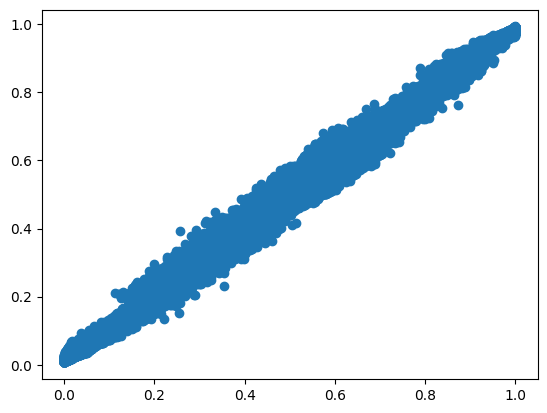

In [234]:
# plt.plot(p, trace.posterior["trees"].values.mean(0).mean)
probs = sp.stats.norm.cdf(trace.posterior.trees.values)
plt.scatter(p,probs.mean(0).mean(0))
# 47

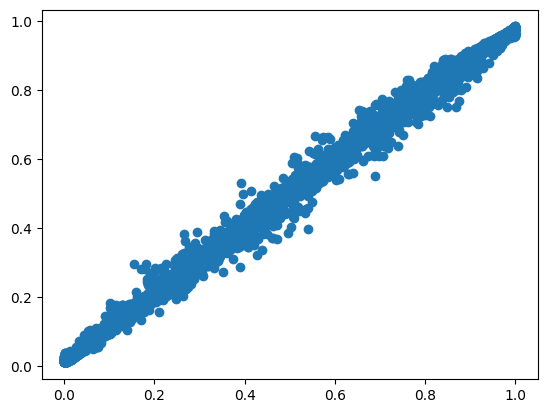

In [ ]:
probs = sp.stats.norm.cdf(trace.posterior.trees.values)
plt.scatter(p,probs.mean(0).mean(0))
# 43

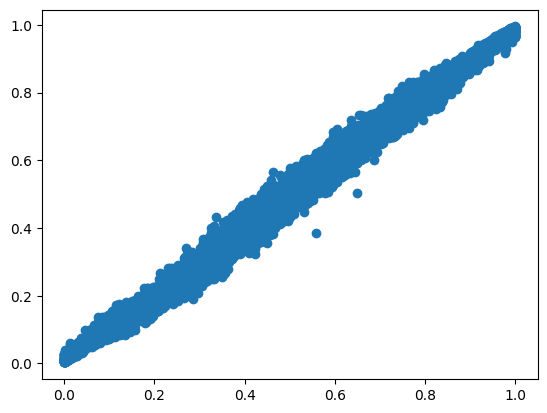

In [217]:
probs = sp.stats.norm.cdf(trace.posterior.trees.values)
plt.scatter(p,probs.mean(0).mean(0))
# 47

In [226]:
np.quantile(probs.mean(2).flatten(), [0.025,0.975])

array([0.49645651, 0.51221898])

In [164]:
# Look at the final inclusion counts across the chains
var_counts = trace.sample_stats["variable_inclusion"].values.sum(axis=(0, 1))
print("Variable Splits:", var_counts)

Variable Splits: [32044 20257 20370 68588 17260]


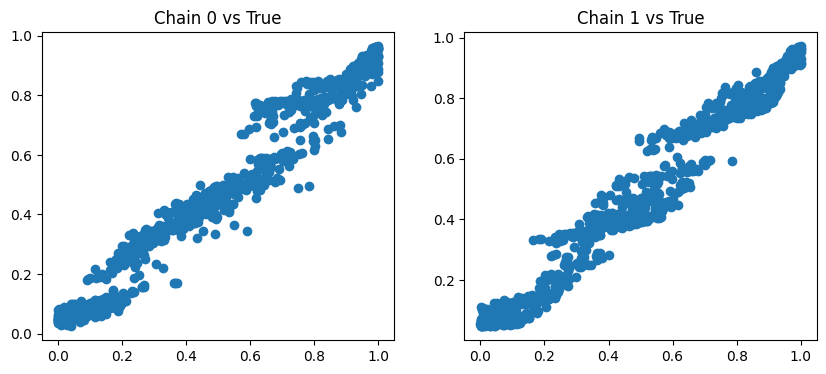

In [165]:
import matplotlib.pyplot as plt

probs_chain_0 = sp.stats.norm.cdf(trace.posterior.trees.isel(chain=0).values).mean(0)
probs_chain_1 = sp.stats.norm.cdf(trace.posterior.trees.isel(chain=1).values).mean(0)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title("Chain 0 vs True")
plt.scatter(p, probs_chain_0)

plt.subplot(1, 2, 2)
plt.title("Chain 1 vs True")
plt.scatter(p, probs_chain_1)
plt.show()

In [50]:
@njit
def propose_grow_fake(tree_idx, X, F, T, L, R, V, node_counts):
    current_count = node_counts[tree_idx]
    leaves = get_active_leaves(F[tree_idx], current_count)
    if current_count >= F.shape[1] - 1: return False, -1 
        
    random_idx = np.random.randint(0, len(leaves))
    leaf_to_split = leaves[random_idx]
    
    num_features = X.shape[1]
    split_feature = np.random.randint(0, num_features)
    feat_min, feat_max = np.min(X[:, split_feature]), np.max(X[:, split_feature])
    split_value = np.random.uniform(feat_min, feat_max)
    
    left_child_idx, right_child_idx = current_count, current_count + 1
    
    F[tree_idx, leaf_to_split] = split_feature
    T[tree_idx, leaf_to_split] = split_value
    L[tree_idx, leaf_to_split] = left_child_idx
    R[tree_idx, leaf_to_split] = right_child_idx
    F[tree_idx, left_child_idx] = -1
    F[tree_idx, right_child_idx] = -1
    
    # Give the new leaves some random prediction values so the likelihood changes!
    V[tree_idx, left_child_idx] = np.random.normal(0, 0.5)
    V[tree_idx, right_child_idx] = np.random.normal(0, 0.5)
    
    node_counts[tree_idx] += 2
    return True, leaf_to_split
# =========================================
# 2. THE TEST RUN
# ==========================================
if __name__ == "__main__":
    print("\n--- Initializing Dummy Data & C-Memory ---")
    X_dummy = np.ascontiguousarray(np.random.normal(size=(1000, 5)))
    
    # We create a true relationship so the model has something to learn
    # If X0 > 0, higher chance of event (Y=1)
    true_eta = X_dummy[:, 0] * 1.5
    true_p = 0.5 * (1.0 + np.vectorize(math.erf)(true_eta / 1.414))
    Y_dummy = np.random.binomial(1, true_p)
    
    # Allocate a single tree for testing
    m_trees = 1
    max_nodes = 255
    F = np.full((m_trees, max_nodes), -1, dtype=np.int16)
    L = np.full((m_trees, max_nodes), -1, dtype=np.int16)
    R = np.full((m_trees, max_nodes), -1, dtype=np.int16)
    T = np.zeros((m_trees, max_nodes), dtype=np.float32)
    V = np.zeros((m_trees, max_nodes), dtype=np.float32)
    node_counts = np.ones(m_trees, dtype=np.int16)
    
    # Simulate partial predictions (the rest of the ensemble) being exactly 0
    partial_preds = np.zeros(1000, dtype=np.float32)
    
    print("\n[PHASE 1] Stump Likelihood")
    stump_preds = get_tree_prediction(X_dummy, F[0], T[0], L[0], R[0], V[0])
    stump_ll = calc_probit_loglik(Y_dummy, partial_preds, stump_preds)
    print(f" -> Stump Log-Likelihood: {stump_ll:.4f}")
    
    print("\n[PHASE 2] Mutating Tree (Grow)...")
    # We force it to grow until it splits on X0 (the true feature)
    while True:
        propose_grow_fake(0, X_dummy, F, T, L, R, V, node_counts)
        if F[0, 0] == 0: 
            break
        else:
            # Revert to stump if it picked the wrong feature
            F[0, 0] = -1
            node_counts[0] = 1

    print(f" -> Tree successfully split on Feature 0 (Threshold: {T[0,0]:.4f})")
    
    print("\n[PHASE 3] New Likelihood")
    new_preds = get_tree_prediction(X_dummy, F[0], T[0], L[0], R[0], V[0])
    print(new_preds[1:100])
    new_ll = calc_probit_loglik(Y_dummy, partial_preds, new_preds)
    print(f" -> Mutated Log-Likelihood: {new_ll:.4f}")
    
    ll_diff = new_ll - stump_ll
    print(f"\n[RESULT] Likelihood Delta: {ll_diff:+.4f}")
    if ll_diff > 0:
        print(" -> The mutation IMPROVED the model. Metropolis-Hastings will likely ACCEPT.")
    else:
        print(" -> The mutation WORSENED the model. Metropolis-Hastings will likely REJECT.")


--- Initializing Dummy Data & C-Memory ---

[PHASE 1] Stump Likelihood
 -> Stump Log-Likelihood: -693.1472

[PHASE 2] Mutating Tree (Grow)...
 -> Tree successfully split on Feature 0 (Threshold: -2.0260)

[PHASE 3] New Likelihood
[-0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.10594031 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0

array([0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0,
       0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,